In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Loading the cleaned delivery data
project_path = os.path.dirname(os.getcwd())
data_path = os.path.join(project_path, "data")

df = pd.read_csv(os.path.join(data_path, "deliveries_clean.csv"))

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (295732, 23)


C:\Users\sw\AppData\Local\Temp\ipykernel_14040\4099710330.py:10: DtypeWarning: Columns (0: season) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(os.path.join(data_path, "deliveries_clean.csv"))


,match_id,innings,over,delivery_number,batting_team,batter,bowler,runs_batter,runs_total,wides,...,penalty,is_legal_delivery,bowler_runs,balls_faced,total_wickets,bowler_wickets,date,season,venue,city
0,1082591,1,0,1,Sunrisers Hyderabad,DA Warner,TS Mills,0,0,0,...,0,1,0,1,0,0,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad
1,1082591,1,0,2,Sunrisers Hyderabad,DA Warner,TS Mills,0,0,0,...,0,1,0,1,0,0,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad
2,1082591,1,0,3,Sunrisers Hyderabad,DA Warner,TS Mills,4,4,0,...,0,1,4,1,0,0,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad
3,1082591,1,0,4,Sunrisers Hyderabad,DA Warner,TS Mills,0,0,0,...,0,1,0,1,0,0,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad
4,1082591,1,0,5,Sunrisers Hyderabad,DA Warner,TS Mills,0,2,2,...,0,0,2,0,0,0,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad


In [3]:
# Grouping deliveries by batter to calculate individual performance
batting_stats = df.groupby("batter").agg(
    total_runs=("runs_batter", "sum"),
    balls_faced=("balls_faced", "sum"),
    fours=("runs_batter", lambda x: (x == 4).sum()),
    sixes=("runs_batter", lambda x: (x == 6).sum()),
    matches_played=("match_id", "nunique")
).reset_index()

# Calculating strike rate
batting_stats["strike_rate"] = (
    batting_stats["total_runs"] /
    batting_stats["balls_faced"].replace(0, np.nan) * 100
).round(2)

batting_stats = batting_stats.sort_values(
    "total_runs", ascending=False
)

batting_stats.head(15)

,batter,total_runs,balls_faced,fours,sixes,matches_played,strike_rate
693,V Kohli,9346,6930,847,317,275,134.86
526,RG Sharma,7331,5517,661,324,275,132.88
563,S Dhawan,6769,5326,768,153,221,127.09
159,DA Warner,6567,4702,663,236,184,139.66
311,KL Rahul,5828,4188,509,239,149,139.16
597,SK Raina,5536,4046,506,204,200,136.83
409,MS Dhoni,5439,3957,375,264,241,137.45
52,AM Rahane,5367,4273,540,141,197,125.60
31,AB de Villiers,5181,3411,414,253,170,151.89
627,SV Samson,5181,3671,432,243,185,141.13


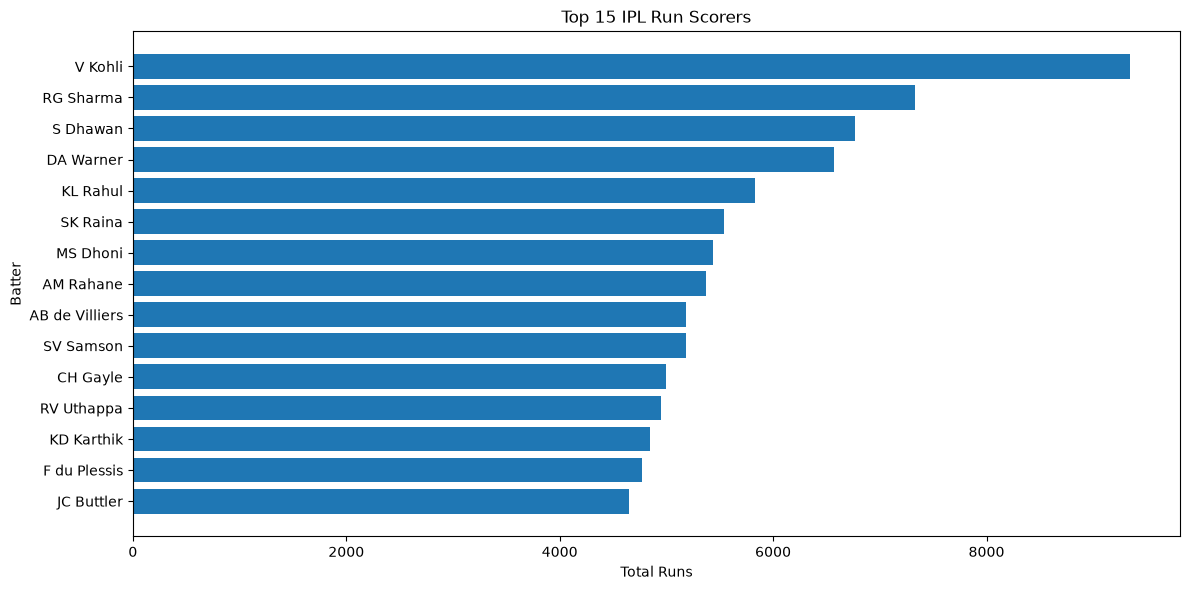

In [4]:
# Finding the 15 highest run scorers
top_scorers = batting_stats.head(15)

plt.figure(figsize=(12, 6))

plt.barh(top_scorers["batter"], top_scorers["total_runs"])

plt.title("Top 15 IPL Run Scorers")
plt.xlabel("Total Runs")
plt.ylabel("Batter")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

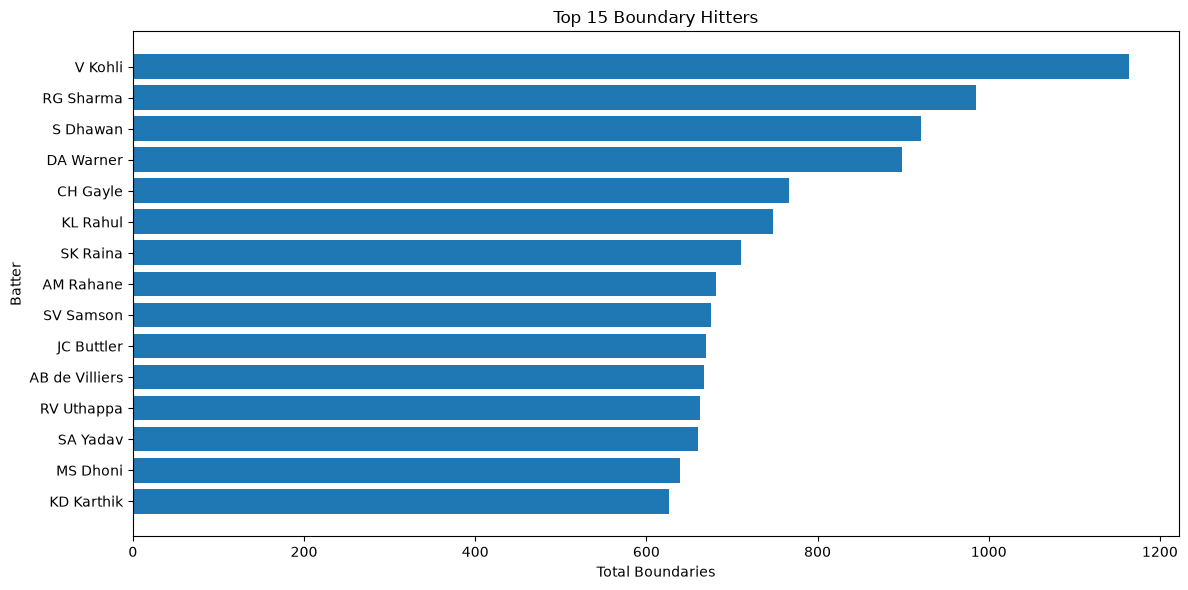

In [5]:
# Comparing batters based on their total boundaries
batting_stats["total_boundaries"] = (
    batting_stats["fours"] + batting_stats["sixes"]
)

top_boundary_hitters = batting_stats.sort_values(
    "total_boundaries", ascending=False
).head(15)

plt.figure(figsize=(12, 6))

plt.barh(
    top_boundary_hitters["batter"],
    top_boundary_hitters["total_boundaries"]
)

plt.title("Top 15 Boundary Hitters")
plt.xlabel("Total Boundaries")
plt.ylabel("Batter")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

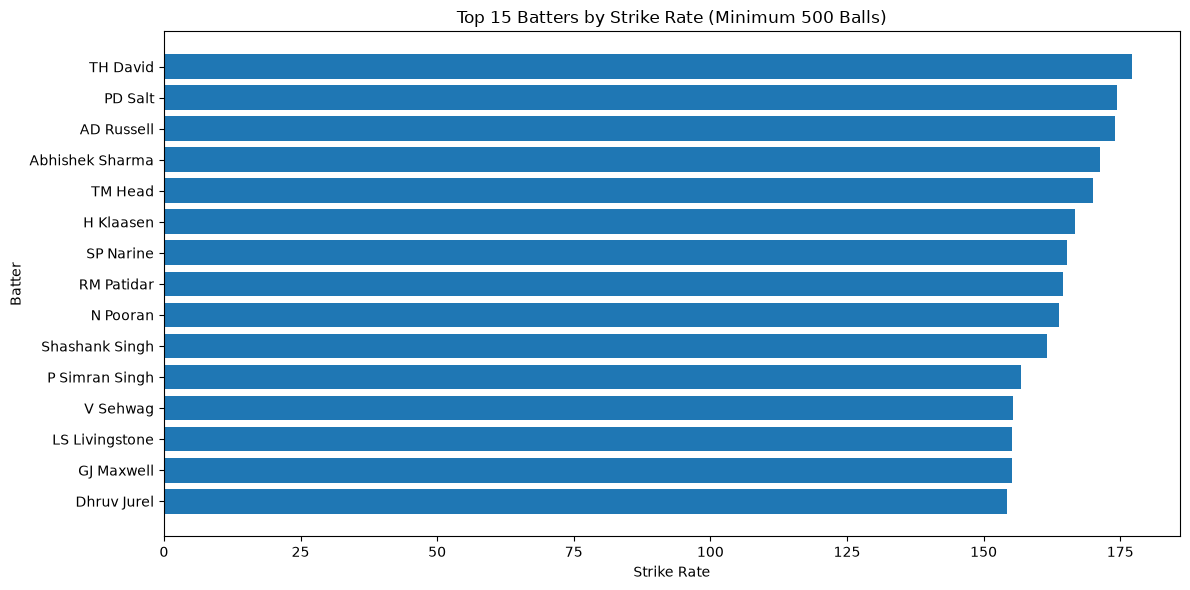

In [6]:
# Considering batters with at least 500 balls faced
regular_batters = batting_stats[
    batting_stats["balls_faced"] >= 500
].copy()

top_strike_rate = regular_batters.sort_values(
    "strike_rate", ascending=False
).head(15)

plt.figure(figsize=(12, 6))

plt.barh(
    top_strike_rate["batter"],
    top_strike_rate["strike_rate"]
)

plt.title("Top 15 Batters by Strike Rate (Minimum 500 Balls)")
plt.xlabel("Strike Rate")
plt.ylabel("Batter")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [7]:
# Calculating average runs per match played
batting_stats["average_runs_per_match"] = (
    batting_stats["total_runs"] /
    batting_stats["matches_played"]
).round(2)

consistent_batters = batting_stats[
    batting_stats["matches_played"] >= 30
].sort_values(
    "average_runs_per_match", ascending=False
).head(15)

consistent_batters[
    ["batter", "matches_played", "total_runs", "average_runs_per_match"]
]

,batter,matches_played,total_runs,average_runs_per_match
103,B Sai Sudharsan,57,2515,44.12
311,KL Rahul,149,5828,39.11
593,SE Marsh,69,2489,36.07
159,DA Warner,184,6567,35.69
135,CH Gayle,141,4997,35.44
651,Shubman Gill,130,4598,35.37
225,H Klaasen,60,2104,35.07
397,ML Hayden,32,1107,34.59
262,JC Buttler,136,4647,34.17
382,MEK Hussey,58,1977,34.09


In [8]:
# Grouping batting performance by season
seasonal_batting = df.groupby(
    ["season", "batter"]
).agg(
    total_runs=("runs_batter", "sum"),
    balls_faced=("balls_faced", "sum"),
    fours=("runs_batter", lambda x: (x == 4).sum()),
    sixes=("runs_batter", lambda x: (x == 6).sum())
).reset_index()

seasonal_batting["strike_rate"] = (
    seasonal_batting["total_runs"] /
    seasonal_batting["balls_faced"].replace(0, np.nan) * 100
).round(2)

seasonal_batting.head()

,season,batter,total_runs,balls_faced,fours,sixes,strike_rate
0,2012,A Ashish Reddy,22,16,3,0,137.5
1,2012,A Chandila,0,1,0,0,0.0
2,2012,A Mishra,8,5,1,0,160.0
3,2012,A Nehra,9,8,1,0,112.5
4,2012,AA Jhunjhunwala,19,20,0,1,95.0


In [9]:
# Finding the highest run scorer for every season
top_scorer_by_season = seasonal_batting.loc[
    seasonal_batting.groupby("season")["total_runs"].idxmax()
].sort_values("season", key=lambda x: x.astype(str))

top_scorer_by_season[
    ["season", "batter", "total_runs", "strike_rate"]
]

,season,batter,total_runs,strike_rate
1934,2007/08,SE Marsh,616,139.68
2048,2009,ML Hayden,572,144.81
2265,2009/10,SR Tendulkar,618,132.62
2321,2011,CH Gayle,608,183.13
21,2012,CH Gayle,325,170.16
2484,2012,AM Rahane,463,137.39
213,2013,MEK Hussey,733,129.51
391,2014,RV Uthappa,660,137.79
451,2015,DA Warner,562,156.55
686,2016,V Kohli,973,152.03


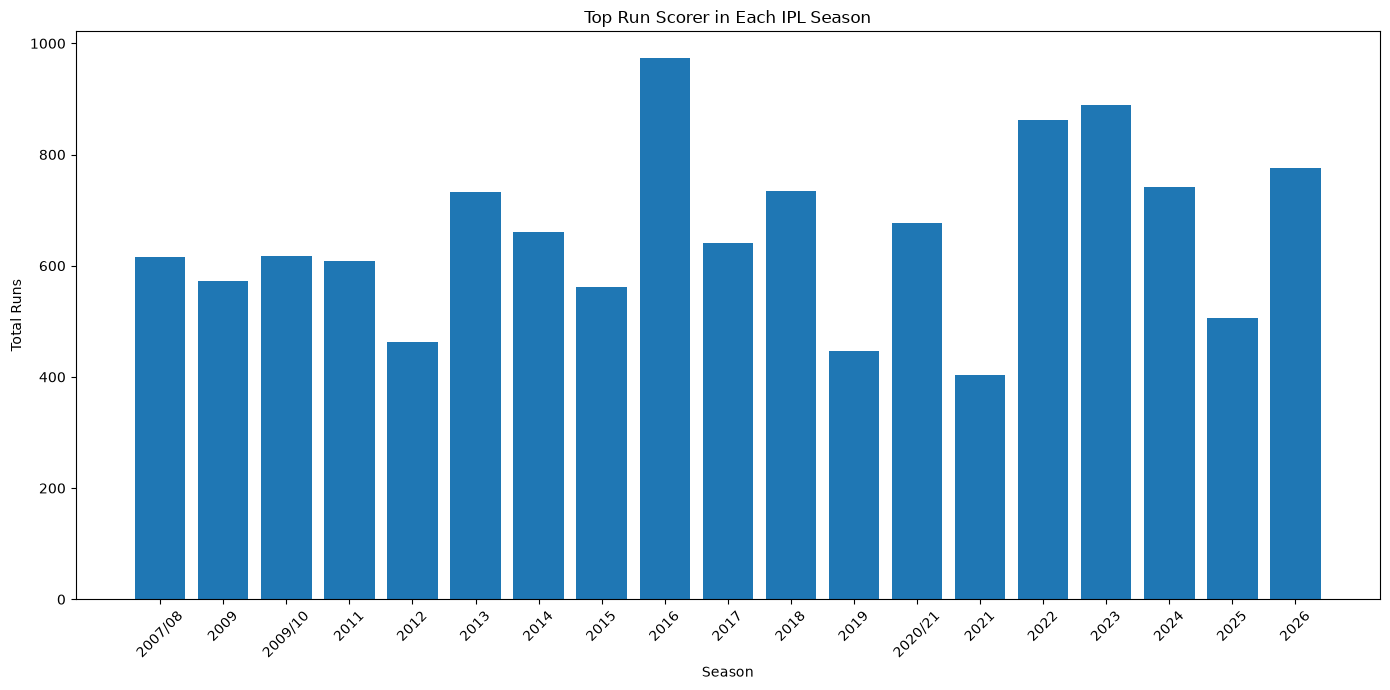

In [10]:
plt.figure(figsize=(14, 7))

plt.bar(
    top_scorer_by_season["season"].astype(str),
    top_scorer_by_season["total_runs"]
)

plt.title("Top Run Scorer in Each IPL Season")
plt.xlabel("Season")
plt.ylabel("Total Runs")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [11]:
# Saving batting results for future use
output_path = os.path.join(project_path, "data")

batting_stats.to_csv(
    os.path.join(output_path, "batting_stats.csv"),
    index=False
)

seasonal_batting.to_csv(
    os.path.join(output_path, "seasonal_batting.csv"),
    index=False
)

top_scorer_by_season.to_csv(
    os.path.join(output_path, "top_scorer_by_season.csv"),
    index=False
)

print("Batting analysis datasets saved successfully!")

Batting analysis datasets saved successfully!
